In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
print("E-Commerce BI Project Started Successfully!")

E-Commerce BI Project Started Successfully!


In [12]:
products = pd.read_csv("Product.csv")
customers = pd.read_csv("customers.csv")
orders = pd.read_csv("orders.csv")

print("All Datasets Loaded Successfully!")

print("Products:", products.shape)
print("Customers:", customers.shape)
print("Orders:", orders.shape)

display(products.head())
display(customers.head())
display(orders.head())

All Datasets Loaded Successfully!
Products: (10, 6)
Customers: (10, 5)
Orders: (15, 6)


,Product_ID,Product_Name,Category,Price,Cost_Price,Stock
0,101,Laptop,Electronics,55000,45000,15
1,102,Smartphone,Electronics,25000,19000,25
2,103,Headphones,Accessories,2000,1200,40
3,104,Keyboard,Accessories,1500,900,50
4,105,Mouse,Accessories,800,400,60


,Customer_ID,Customer_Name,City,Age,Gender
0,201,Aarav Sharma,Jaipur,24,Male
1,202,Ananya Singh,Udaipur,22,Female
2,203,Rohan Verma,Delhi,28,Male
3,204,Meera Gupta,Mumbai,25,Female
4,205,Kabir Khan,Jaipur,30,Male


,Order_ID,Customer_ID,Product_ID,Quantity,Order_Date,Order_Status
0,301,201,101,1,2026-01-05,Delivered
1,302,202,103,2,2026-01-07,Delivered
2,303,203,102,1,2026-01-10,Delivered
3,304,204,105,3,2026-01-12,Pending
4,305,205,104,2,2026-01-15,Delivered


In [13]:

for df in [products, customers, orders]:
    df.columns = df.columns.str.strip()
    df.drop_duplicates(inplace=True)

print("Data Cleaning Completed!")

print("Product Columns:", products.columns.tolist())
print("Customer Columns:", customers.columns.tolist())
print("Order Columns:", orders.columns.tolist())

Data Cleaning Completed!
Product Columns: ['Product_ID', 'Product_Name', 'Category', 'Price', 'Cost_Price', 'Stock']
Customer Columns: ['Customer_ID', 'Customer_Name', 'City', 'Age', 'Gender']
Order Columns: ['Order_ID', 'Customer_ID', 'Product_ID', 'Quantity', 'Order_Date', 'Order_Status']


In [14]:
print("===== E-COMMERCE BUSINESS REPORT =====")

print("Total Products:", len(products))
print("Total Customers:", len(customers))
print("Total Orders:", len(orders))

print("\nOrder Data Summary:")
display(orders.describe(include="all"))

===== E-COMMERCE BUSINESS REPORT =====
Total Products: 10
Total Customers: 10
Total Orders: 15

Order Data Summary:


,Order_ID,Customer_ID,Product_ID,Quantity,Order_Date,Order_Status
count,15.000000,15.000000,15.000000,15.000000,15,15
unique,NaN,NaN,NaN,NaN,15,3
top,NaN,NaN,NaN,NaN,2026-01-05,Delivered
freq,NaN,NaN,NaN,NaN,1,11
mean,308.000000,204.666667,104.933333,1.466667,NaN,NaN
std,4.472136,2.845213,2.963267,0.639940,NaN,NaN
min,301.000000,201.000000,101.000000,1.000000,NaN,NaN
25%,304.500000,202.500000,102.500000,1.000000,NaN,NaN
50%,308.000000,204.000000,105.000000,1.000000,NaN,NaN
75%,311.500000,206.500000,107.500000,2.000000,NaN,NaN


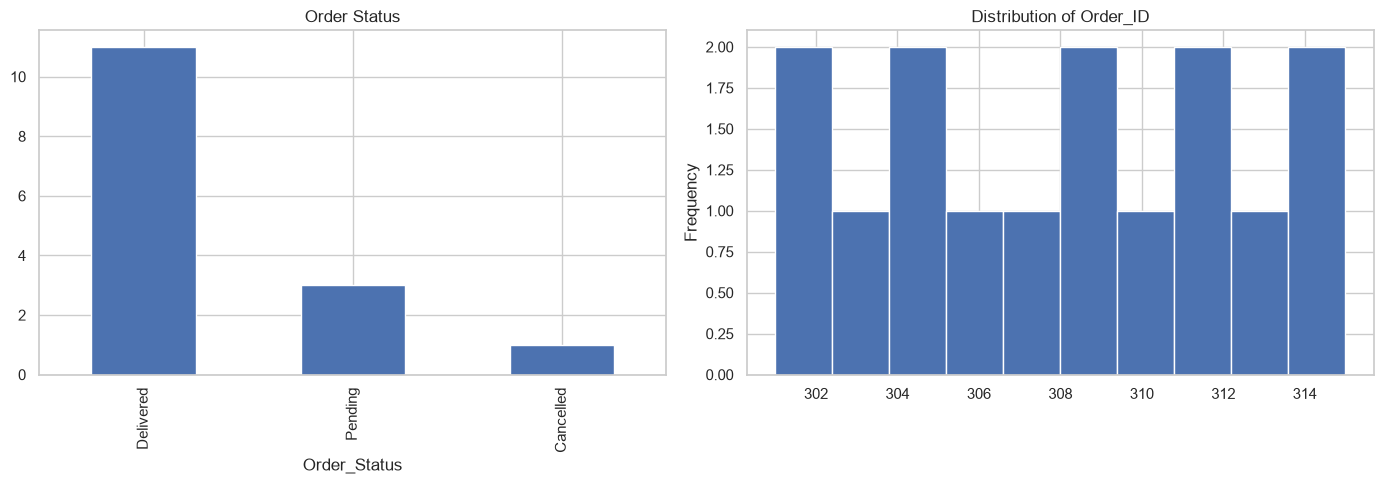

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# First chart: Order status
status_col = next(
    (c for c in orders.columns if "status" in c.lower()), None
)

if status_col:
    orders[status_col].value_counts().plot(
        kind="bar", ax=axes[0], title="Order Status"
    )
else:
    axes[0].text(0.5, 0.5, "No Status Column Found",
                 ha="center", va="center")

# Second chart: Numeric data distribution
numeric_cols = orders.select_dtypes(include="number").columns

if len(numeric_cols) > 0:
    orders[numeric_cols[0]].plot(
        kind="hist", ax=axes[1], title=f"Distribution of {numeric_cols[0]}"
    )
else:
    axes[1].text(0.5, 0.5, "No Numeric Column Found",
                 ha="center", va="center")

plt.tight_layout()
plt.show()